# Milestone 2: Segmentation pipeline
**SurfaceGuard AI** (industrial surface anomaly segmentation, 4 classes, 128x800 grayscale strips).

Pipeline: data split from Milestone 1 -> `Dataset`/`DataLoader` with augmentation -> U-Net from scratch (random init) -> BCE + soft Dice loss -> W&B tracking -> threshold selection on validation -> RLE encoding -> `submission.csv`.
Run: Kaggle, GPU on, secret `WANDB_API_KEY` attached, `holdout.csv` from Milestone 1 available.

In [1]:
import os, glob, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", DEVICE)

IMG_H, IMG_W = 128, 800
CANVAS_PIXELS = IMG_H * IMG_W
DEFECT_TYPES = ["defect_a", "defect_b", "defect_c", "defect_d"]

PyTorch 2.11.0+cu128 | device: cuda


## 2. Helpers: RLE and metric
`rle_decode`/`rle_encode` use the 1-based, column-major convention. `competition_score` implements the three-part metric (0.70 foreground Dice, 0.20 false-positive score, 0.10 empty accuracy).

In [2]:
def rle_decode(rle, shape=(IMG_H, IMG_W)):
    """1-based, column-major RLE string -> binary (H, W) mask."""
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if isinstance(rle, str) and rle.strip():
        tokens = [int(t) for t in rle.split()]
        starts = np.array(tokens[0::2]) - 1
        ends = starts + np.array(tokens[1::2])
        for s, e in zip(starts, ends):
            flat[max(s, 0):min(e, flat.size)] = 1
    return flat.reshape(shape, order="F")

def rle_encode(mask):
    """Binary (H, W) mask -> 1-based, column-major RLE string. Empty mask -> " "."""
    flat = np.asarray(mask, dtype=np.uint8).flatten(order="F")
    padded = np.concatenate([[0], flat, [0]])
    changes = np.where(padded[1:] != padded[:-1])[0] + 1   
    changes[1::2] -= changes[::2]                         
    return " ".join(map(str, changes)) if len(changes) else " "

def dice_empty_aware(inter, pred_area, gt_area):
    """Dice with convention: both empty -> 1, exactly one empty -> 0."""
    inter, pred_area, gt_area = (np.asarray(a, dtype=np.float64) for a in (inter, pred_area, gt_area))
    denom = pred_area + gt_area
    dice = np.where(denom > 0, 2 * inter / np.maximum(denom, 1), 0.0)
    return np.where((pred_area == 0) & (gt_area == 0), 1.0, dice)

def competition_score(inter, pred_area, gt_area, canvas=CANVAS_PIXELS, weights=(0.70, 0.20, 0.10)):
    inter, pred_area, gt_area = (np.asarray(a, dtype=np.float64) for a in (inter, pred_area, gt_area))
    positive = gt_area > 0
    empty = ~positive
    dice = dice_empty_aware(inter, pred_area, gt_area)
    fg = dice[positive].mean()
    fp = 1 - (pred_area[empty] / canvas).mean()
    ea = (pred_area[empty] == 0).mean()
    w_fg, w_fp, w_ea = weights
    return {"foreground_dice": fg, "false_positive_score": fp, "empty_accuracy": ea,
            "score": w_fg * fg + w_fp * fp + w_ea * ea}

In [3]:

rng = np.random.default_rng(0)
for _ in range(200):
    m = (rng.random((IMG_H, IMG_W)) > 0.97).astype(np.uint8)
    assert np.array_equal(rle_decode(rle_encode(m)), m)
assert rle_encode(np.zeros((IMG_H, IMG_W))) == " "
print("rle_encode / rle_decode round trip OK")

rle_encode / rle_decode round trip OK


## 3. Data paths and split
The validation set is the same stratified holdout as Milestone 1 (seed 42, 9,114 train / 2,279 validation images), so all models are comparable.

In [4]:
def find_one(pattern_list):
    for p in pattern_list:
        hits = glob.glob(p, recursive=True)
        if hits:
            return sorted(hits)[0]
    raise FileNotFoundError(f"None of {pattern_list} matched")

TRAIN_CSV  = find_one(["/kaggle/input/**/train.csv"])
SAMPLE_CSV = find_one(["/kaggle/input/**/sample_submission.csv"])
HOLDOUT_CSV = find_one(["/kaggle/working/holdout.csv", "/kaggle/input/**/holdout.csv"])
print(TRAIN_CSV, SAMPLE_CSV, HOLDOUT_CSV, sep="\n")

IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
def build_image_index(root="/kaggle/input"):
    """image_id (file name without extension) -> full path."""
    index = {}
    for dirpath, _, files in os.walk(root):
        for f in files:
            if f.lower().endswith(IMG_EXT):
                index[os.path.splitext(f)[0]] = os.path.join(dirpath, f)
    return index

IMAGE_INDEX = build_image_index()
print("images found:", len(IMAGE_INDEX))

/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
/kaggle/input/notebooks/mruniksurya/milestone-1/holdout.csv
images found: 14400


In [5]:
train_long = pd.read_csv(TRAIN_CSV)
rle_table = train_long.pivot(index="image_id", columns="defect_type", values="mask_rle")[DEFECT_TYPES]

hold = pd.read_csv(HOLDOUT_CSV)
print("holdout.csv columns:", list(hold.columns))

if "split" in hold.columns:
    val_ids = hold.loc[hold["split"].astype(str).str.lower().isin(["val", "valid", "validation", "holdout"]), "image_id"]
elif "is_val" in hold.columns:
    val_ids = hold.loc[hold["is_val"].astype(bool), "image_id"]
else:
    val_ids = hold["image_id"]
val_ids = sorted(set(val_ids))
train_ids = sorted(set(rle_table.index) - set(val_ids))
print("train images:", len(train_ids), "| validation images:", len(val_ids))
assert len(val_ids) == 2279 and len(train_ids) == 9114, "split differs from Milestone 1: check holdout.csv"
assert set(train_ids).issubset(IMAGE_INDEX) and set(val_ids).issubset(IMAGE_INDEX), "some image files not found"

holdout.csv columns: ['image_id', 'combo', 'split']
train images: 9114 | validation images: 2279


In [6]:
sample = random.sample(train_ids, 300)
px = np.stack([np.asarray(Image.open(IMAGE_INDEX[i]).convert("L"), dtype=np.float32) / 255. for i in sample])
IMG_MEAN, IMG_STD = float(px.mean()), float(px.std())
print(f"mean={IMG_MEAN:.4f} std={IMG_STD:.4f}")
del px

mean=0.3314 std=0.1892


## 4. Dataset, augmentation, DataLoaders
Augmentation (train only): horizontal/vertical flip applied to image and masks together; brightness and contrast on the image only. Images normalised with training mean/std. `DEBUG=True` runs a quick smoke test.

In [7]:
def augment_pair(img, masks):
    """img (H,W), masks (4,H,W). Geometric ops hit both; brightness/contrast only the image."""
    if random.random() < 0.5:                       
        img, masks = img[:, ::-1], masks[:, :, ::-1]
    if random.random() < 0.5:                      
        img, masks = img[::-1, :], masks[:, ::-1, :]
    contrast = random.uniform(0.8, 1.2)
    brightness = random.uniform(-0.1, 0.1)
    img = np.clip(img * contrast + brightness, 0.0, 1.0)
    return img, masks

class SurfaceDataset(Dataset):
    """Returns (image[1,H,W] float, mask[4,H,W] float). masks=None for test images."""
    def __init__(self, image_ids, image_index, rle_table=None, augment=False, mean=0.5, std=0.25):
        self.ids = list(image_ids)
        self.index = image_index
        self.rows = rle_table.loc[self.ids, DEFECT_TYPES].values if rle_table is not None else None
        self.augment, self.mean, self.std = augment, mean, std

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        img = np.asarray(Image.open(self.index[self.ids[i]]).convert("L"), dtype=np.float32) / 255.
        assert img.shape == (IMG_H, IMG_W), f"unexpected image shape {img.shape}"
        if self.rows is not None:
            masks = np.stack([rle_decode(r) for r in self.rows[i]]).astype(np.float32)
        else:
            masks = np.zeros((len(DEFECT_TYPES), IMG_H, IMG_W), dtype=np.float32)
        if self.augment:
            img, masks = augment_pair(img, masks)
        img = (img - self.mean) / self.std
        return (torch.from_numpy(np.ascontiguousarray(img))[None],
                torch.from_numpy(np.ascontiguousarray(masks)))

In [8]:
DEBUG = False         
BATCH_SIZE = 16
tr_ids = train_ids[:64] if DEBUG else train_ids
va_ids = val_ids[:32] if DEBUG else val_ids

train_ds = SurfaceDataset(tr_ids, IMAGE_INDEX, rle_table, augment=True,  mean=IMG_MEAN, std=IMG_STD)
val_ds   = SurfaceDataset(va_ids, IMAGE_INDEX, rle_table, augment=False, mean=IMG_MEAN, std=IMG_STD)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

x, y = next(iter(train_loader))
print("image batch:", tuple(x.shape), x.dtype, "| mask batch:", tuple(y.shape), y.dtype)

image batch: (16, 1, 128, 800) torch.float32 | mask batch: (16, 4, 128, 800) torch.float32


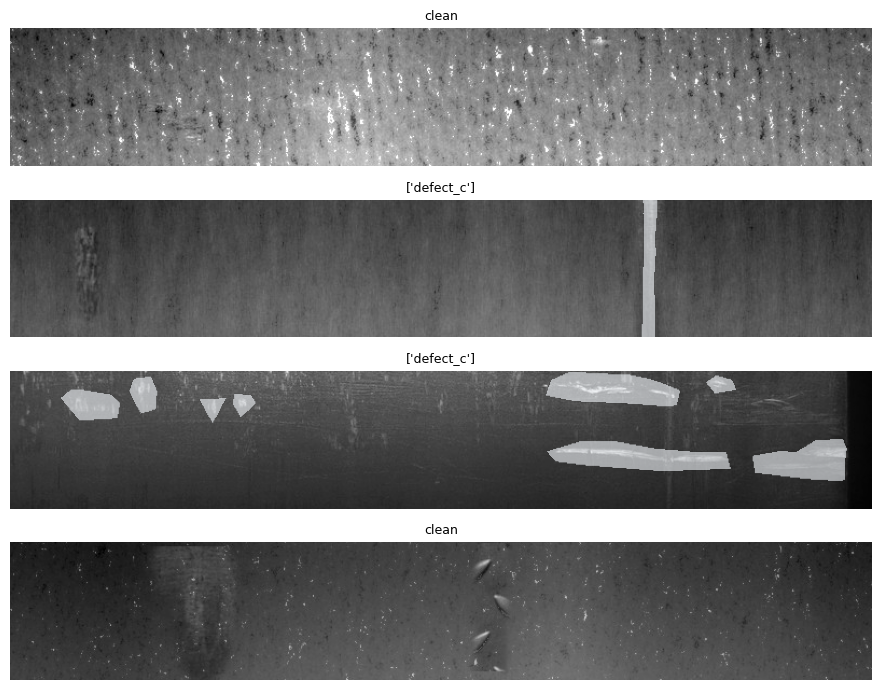

In [9]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(4, 1, figsize=(12, 7))
for k in range(4):
    img = x[k, 0].numpy() * IMG_STD + IMG_MEAN
    axes[k].imshow(img, cmap="gray", vmin=0, vmax=1)
    for c, color in zip(range(4), ["Reds", "Greens", "Blues", "Oranges"]):
        m = np.ma.masked_where(y[k, c].numpy() == 0, y[k, c].numpy())
        axes[k].imshow(m, cmap=color, alpha=0.6)
    present = [DEFECT_TYPES[c] for c in range(4) if y[k, c].sum() > 0]
    axes[k].set_title(str(present) if present else "clean", fontsize=9); axes[k].axis("off")
plt.tight_layout(); plt.show()

## 5. Model: U-Net from scratch
4 encoder levels (32 to 256 channels), 512-channel bottleneck, skip connections by concatenation, 1x1 head with 4 independent logits. No pretrained weights.

In [10]:
class DoubleConv(nn.Module):
    """(Conv3x3 -> BatchNorm -> ReLU) x 2 : the basic U-Net building block."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x):
        return self.block(x)

class UNetScratch(nn.Module):
    """U-Net with random initialisation (no pretrained weights). Input (B,1,H,W) -> logits (B,4,H,W)."""
    def __init__(self, in_ch=1, n_classes=4, base=32):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]           # 32, 64, 128, 256, 512
        self.enc1, self.enc2 = DoubleConv(in_ch, c[0]), DoubleConv(c[0], c[1])
        self.enc3, self.enc4 = DoubleConv(c[1], c[2]), DoubleConv(c[2], c[3])
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(c[3], c[4])
        self.up4, self.dec4 = nn.ConvTranspose2d(c[4], c[3], 2, stride=2), DoubleConv(c[3] * 2, c[3])
        self.up3, self.dec3 = nn.ConvTranspose2d(c[3], c[2], 2, stride=2), DoubleConv(c[2] * 2, c[2])
        self.up2, self.dec2 = nn.ConvTranspose2d(c[2], c[1], 2, stride=2), DoubleConv(c[1] * 2, c[1])
        self.up1, self.dec1 = nn.ConvTranspose2d(c[1], c[0], 2, stride=2), DoubleConv(c[0] * 2, c[0])
        self.head = nn.Conv2d(c[0], n_classes, kernel_size=1)         # 4 independent logits per pixel

    def forward(self, x):
        e1 = self.enc1(x)                       # (B, 32, 128, 800)
        e2 = self.enc2(self.pool(e1))           # (B, 64,  64, 400)
        e3 = self.enc3(self.pool(e2))           # (B,128,  32, 200)
        e4 = self.enc4(self.pool(e3))           # (B,256,  16, 100)
        b  = self.bottleneck(self.pool(e4))     # (B,512,   8,  50)
        d4 = self.dec4(torch.cat([self.up4(b),  e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head(d1)                    # raw logits, no sigmoid here

model_test = UNetScratch().to(DEVICE)
with torch.no_grad():
    out = model_test(torch.randn(2, 1, IMG_H, IMG_W, device=DEVICE))
print("output shape:", tuple(out.shape))        # expect (2, 4, 128, 800)
print(f"trainable parameters: {sum(p.numel() for p in model_test.parameters() if p.requires_grad):,}")
del model_test

output shape: (2, 4, 128, 800)
trainable parameters: 7,762,564


## 6. Loss and validation metric
Loss = BCE-with-logits + soft Dice on defect-containing pairs. Validation reports loss and the official-style score for thresholds 0.3 to 0.9.

In [11]:
def dice_loss_on_positives(logits, targets, eps=1e-6):
    """Soft Dice loss averaged over the (image, class) pairs that really contain a defect."""
    probs = torch.sigmoid(logits)
    inter = (probs * targets).sum((2, 3))
    denom = probs.sum((2, 3)) + targets.sum((2, 3))
    dice = (2 * inter + eps) / (denom + eps)
    pos = targets.sum((2, 3)) > 0
    return (1 - dice[pos]).mean() if pos.any() else logits.sum() * 0.0

def loss_fn(logits, targets):
    return F.binary_cross_entropy_with_logits(logits, targets) + dice_loss_on_positives(logits, targets)

TAUS = (0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)

@torch.no_grad()
def evaluate(model, loader, taus=TAUS):
    """Validation loss + official-style score for every threshold in taus."""
    model.eval()
    loss_sum, n = 0.0, 0
    acc = {t: {"inter": [], "pred": [], "gt": []} for t in taus}
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        logits = model(x)
        loss_sum += loss_fn(logits, y).item() * x.size(0); n += x.size(0)
        probs = torch.sigmoid(logits)
        gt = y.sum((2, 3)).flatten().cpu()
        for t in taus:
            pb = (probs > t).float()
            acc[t]["inter"].append((pb * y).sum((2, 3)).flatten().cpu())
            acc[t]["pred"].append(pb.sum((2, 3)).flatten().cpu())
            acc[t]["gt"].append(gt)
    stats = {t: competition_score(*(torch.cat(acc[t][k]).numpy() for k in ("inter", "pred", "gt")))
             for t in taus}
    return loss_sum / n, stats

## 7. Training with Weights & Biases

In [12]:
from kaggle_secrets import UserSecretsClient
import wandb
wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY"))
WANDB_ENTITY  = "22f2001613-indian-institute-of-technology-madras"
WANDB_PROJECT = "22f2001613-t32026"

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 22f2001613 (22f2001613-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [13]:
CFG = {
    "run_name": "m2-unet-scratch-v1", "tags": ["milestone-2", "from-scratch"],
    "model": "UNetScratch(base=32)", "epochs": 1 if DEBUG else 15, "batch_size": BATCH_SIZE,
    "lr": 1e-3, "weight_decay": 1e-4, "optimizer": "AdamW", "loss": "BCE + soft Dice (positives)",
    "augment": "hflip, vflip, brightness, contrast", "img_size": [IMG_H, IMG_W],
    "n_train": len(tr_ids), "n_val": len(va_ids), "seed": SEED,
}
CKPT_PATH = "/kaggle/working/best_unet_scratch.pt"

def train_model(cfg):
    model = UNetScratch().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    run = wandb.init(entity=WANDB_ENTITY, project=WANDB_PROJECT, name=cfg["run_name"],
                     config=cfg, tags=cfg["tags"])
    best = -1.0
    for epoch in range(1, cfg["epochs"] + 1):
        model.train(); t0 = time.time(); run_loss, n = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad()                    
            loss = loss_fn(model(x), y)        
            loss.backward()                    
            opt.step()                         
            run_loss += loss.item() * x.size(0); n += x.size(0)
        val_loss, st = evaluate(model, val_loader)
        s = st[0.5]
        wandb.log({"epoch": epoch, "train/loss": run_loss / n, "val/loss": val_loss,
                   "val/score@0.5": s["score"], "val/fg_dice@0.5": s["foreground_dice"],
                   "val/fp_score@0.5": s["false_positive_score"], "val/empty_acc@0.5": s["empty_accuracy"],
                   "epoch_time_s": time.time() - t0})
        print(f"epoch {epoch:02d} | train {run_loss/n:.4f} | val {val_loss:.4f} | "
              f"score@0.5 {s['score']:.4f} | fgDice {s['foreground_dice']:.4f} | {time.time()-t0:.0f}s")
        if s["score"] > best:
            best = s["score"]; torch.save(model.state_dict(), CKPT_PATH)
    # final threshold sweep with the best checkpoint
    model.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE))
    _, st = evaluate(model, val_loader)
    table = wandb.Table(columns=["tau", "score", "fg_dice", "fp_score", "empty_acc"],
                        data=[[t, v["score"], v["foreground_dice"], v["false_positive_score"], v["empty_accuracy"]]
                              for t, v in st.items()])
    best_tau = max(st, key=lambda t: st[t]["score"])
    wandb.log({"threshold_sweep": table})
    run.summary.update({"best_val_score": st[best_tau]["score"], "best_tau": best_tau})
    run.finish()
    return model, best_tau, st

model, BEST_TAU, sweep = train_model(CFG)
for t, v in sweep.items():
    print(f"tau {t:.1f}: score {v['score']:.4f} | fgDice {v['foreground_dice']:.4f} | fp {v['false_positive_score']:.4f} | emptyAcc {v['empty_accuracy']:.4f}")
print("chosen threshold:", BEST_TAU)

wandb: setting up run 34c5iose
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261024_032706-34c5iose
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run m2-unet-scratch-v1
wandb: ⭐️ View project at https://wandb.ai/22f2001613-indian-institute-of-technology-madras/22f2001613-t32026
wandb: 🚀 View run at https://wandb.ai/22f2001613-indian-institute-of-technology-madras/22f2001613-t32026/runs/34c5iose


epoch 01 | train 0.9243 | val 0.7363 | score@0.5 0.4831 | fgDice 0.3591 | 362s
epoch 02 | train 0.6923 | val 0.6817 | score@0.5 0.5002 | fgDice 0.3948 | 373s
epoch 03 | train 0.6500 | val 0.6228 | score@0.5 0.5390 | fgDice 0.4671 | 371s
epoch 04 | train 0.6317 | val 0.6151 | score@0.5 0.5554 | fgDice 0.4484 | 373s
epoch 05 | train 0.6119 | val 0.6117 | score@0.5 0.5486 | fgDice 0.4529 | 370s
epoch 06 | train 0.6032 | val 0.5970 | score@0.5 0.5583 | fgDice 0.4776 | 372s
epoch 07 | train 0.5881 | val 0.5806 | score@0.5 0.5657 | fgDice 0.4904 | 371s
epoch 08 | train 0.5814 | val 0.5803 | score@0.5 0.5652 | fgDice 0.4704 | 373s
epoch 09 | train 0.5748 | val 0.5582 | score@0.5 0.5854 | fgDice 0.5009 | 371s
epoch 10 | train 0.5676 | val 0.5577 | score@0.5 0.5768 | fgDice 0.5029 | 371s
epoch 11 | train 0.5599 | val 0.5513 | score@0.5 0.5833 | fgDice 0.5103 | 372s
epoch 12 | train 0.5476 | val 0.5273 | score@0.5 0.5949 | fgDice 0.5245 | 372s
epoch 13 | train 0.5416 | val 0.5518 | score@0.5 0.5

wandb: uploading artifact run-34c5iose-threshold_sweep; updating run metadata
wandb: uploading artifact run-34c5iose-threshold_sweep; uploading history steps 15-15, summary
wandb: uploading artifact run-34c5iose-threshold_sweep
wandb: uploading media/table/threshold_sweep_15_699ff0de2acda21f7a34.table.json; uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: uploading media/table/threshold_sweep_15_699ff0de2acda21f7a34.table.json; uploading wandb-summary.json; uploading config.yaml
wandb: uploading data
wandb: 
wandb: Run history:
wandb:             epoch ▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
wandb:      epoch_time_s ▁█▇█▆▇▇█▇▇▇▇▇█▇
wandb:        train/loss █▄▃▃▂▂▂▂▂▂▂▁▁▁▁
wandb: val/empty_acc@0.5 ▆▄▁█▅▄▃▆▆▄▄▄▄▆▄
wandb:   val/fg_dice@0.5 ▁▃▆▅▅▆▇▆▇▇▇████
wandb:  val/fp_score@0.5 ▂▅▁▆▆▃▄█▆▆▅▇▅▆▆
wandb:          val/loss █▆▄▄▄▃▃▃▂▂▂▁▂▁▁
wandb:     val/score@0.5 ▁▂▄▅▅▅▆▆▇▇▇█▇█▇
wandb: 
wandb: Run summary:
wandb:          best_tau 0.8
wandb:    best_val_score 0.60276
wandb:          

tau 0.3: score 0.6007 | fgDice 0.5262 | fp 0.9876 | emptyAcc 0.3483
tau 0.4: score 0.6014 | fgDice 0.5248 | fp 0.9883 | emptyAcc 0.3634
tau 0.5: score 0.6020 | fgDice 0.5233 | fp 0.9890 | emptyAcc 0.3790
tau 0.6: score 0.6022 | fgDice 0.5215 | fp 0.9897 | emptyAcc 0.3926
tau 0.7: score 0.6026 | fgDice 0.5190 | fp 0.9905 | emptyAcc 0.4122
tau 0.8: score 0.6028 | fgDice 0.5145 | fp 0.9917 | emptyAcc 0.4427
tau 0.9: score 0.5997 | fgDice 0.4996 | fp 0.9943 | emptyAcc 0.5109
chosen threshold: 0.8
